[Data Reshaping](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data_reshaping.html) ended with a condition: two tables can be joined
row by row only once each row means the same thing in both. This chapter does the
joining. Real analyses rarely start from a single table. The information you need is
split across files — one per region or per year, one holding measurements and another
holding descriptions — and the first job is often to put it back together.

There are two basic ways to combine tables. When they hold the same kind of rows, you
stack them. When they hold different information about the same things, you match their
rows on a shared key. Matching is where the surprises live: rows that find no partner,
keys that appear twice, names spelled differently in two sources. So, as in the last two
chapters, the habit to build is checking the result before you trust it.

By the end of this chapter you should be able to:

- Stack tables that share their columns with `pd.concat()`, record which piece each row came from, and check the row count.
- Combine tables that share a key with `merge()`, on one or several key columns, including keys with different names (`left_on=`, `right_on=`).
- Choose `how=` (`"inner"`, `"left"`, `"right"`, `"outer"`), predict which rows survive, and use `indicator=True` to see where each row came from.
- Check a merge before trusting it: compare row counts, enforce key uniqueness with `validate=`, and decide what the missing values from unmatched keys mean.

Complete the [practice activity](#practice-activity-stack-match-and-check)
after the worked examples.

## Set Up Your Chapter Files {#set-up-your-chapter-files}

Download the [Combining Datasets practice kit](https://lizhen0909.github.io/stat303-1-sec20-coursebook/downloads/combining-datasets-practice.zip).
Extract `stat303-combining-datasets` inside the `chapters` folder of your `stat303-1`
course folder, open `stat303-1` in VS Code, and select the course environment. The
terminal opens in `stat303-1`, so move it into the kit with `cd chapters` and then
`cd stat303-combining-datasets` before you render the activity.

```text
stat303-1/
├── .venv/
├── assignments/
└── chapters/
    └── stat303-combining-datasets/
        ├── combining_datasets_examples.ipynb
        ├── activity14.ipynb
        ├── README.md
        └── data/
            ├── gdp_lifeExpec_Africa.csv
            ├── gdp_lifeExpec_Americas.csv
            ├── gdp_lifeExpec_Asia.csv
            ├── gdp_lifeExpec_Europe.csv
            ├── gdp_lifeExpec_Oceania.csv
            └── country-capital-lat-long-population.csv
```

Run `combining_datasets_examples.ipynb` for the lesson and complete `activity14.ipynb`
for your own activity report, with `stat303-combining-datasets` as the notebook working
folder. Every file is read with a relative path such as
`"data/gdp_lifeExpec_Asia.csv"`, so the notebooks find their data only when that folder
is the working folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Environment check:** This chapter uses NumPy, pandas, matplotlib, and seaborn, all of
which are already in the course environment. If an import fails, check the selected
notebook kernel first: it must be the course environment, `stat303-1/.venv`, as in
[Project Environments, Packages, and File Paths](https://lizhen0909.github.io/stat303-1-sec20-coursebook/python_venv.html#install-packages-in-the-intended-environment).

## Why combine datasets

**Why combine?**

- **Information is distributed.** Customer details live in one table and purchases in
  another; product descriptions are separate from sales; a survey's answers are split
  across several files.
- **Data comes from several sources.** Internal records meet external data — a company's
  sales with public economic indicators, or a course's grades with its attendance log.
- **Data is split for storage.** One file per month, per region, or per year is common,
  and an analysis across all of them needs them in one table.
- **An analysis needs more columns.** Adding a population, a region, or a category from a
  second table makes new comparisons possible.

Two operations cover nearly every case:

| Operation | Tool | The tables share | Result |
|---|---|---|---|
| **Stack** | `pd.concat()` | The same columns, different rows | More rows |
| **Match** | `df.merge()` | A key column, different information | More columns, rows paired by key |

## Stack rows: `pd.concat()`

The Gapminder data from the last two chapters arrives here in pieces: one file per
continent, each with the same five columns. Combining them is stacking, and
`pd.concat()`, which you met adding a row in Data Reshaping, does it for a whole list
of tables.

None of the files has a `continent` column — the continent is in the file name. Adding
it as each file is read keeps that information once the pieces are stacked. A `for` loop
reads each file, adds the column, and collects the pieces in a list:

In [2]:
pieces = []
for continent in ["Africa", "Americas", "Asia", "Europe", "Oceania"]:
    piece = pd.read_csv(f"data/gdp_lifeExpec_{continent}.csv")
    piece["continent"] = continent
    print(continent, piece.shape)
    pieces.append(piece)

gapminder = pd.concat(pieces, ignore_index=True)
print("stacked:", gapminder.shape)
gapminder.head()

Africa (624, 6)
Americas (300, 6)
Asia (396, 6)
Europe (360, 6)
Oceania (24, 6)
stacked: (1704, 6)


,country,year,lifeExp,pop,gdpPercap,continent
0,Algeria,1952,43.077,9279525,2449.008185,Africa
1,Algeria,1957,45.685,10270856,3013.976023,Africa
2,Algeria,1962,48.303,11000948,2550.816880,Africa
3,Algeria,1967,51.407,12760499,3246.991771,Africa
4,Algeria,1972,54.518,14760787,4182.663766,Africa


624 + 300 + 396 + 360 + 24 = 1,704 rows: the stacked table has exactly the rows of its
pieces, which is the check to make after any stack. `ignore_index=True` numbers the
stacked rows 0 to 1,703; without it, each piece keeps its own numbering and row labels
repeat.

`concat()` lines up columns **by name**. A column that some pieces lack is filled with
`NaN` in the rows from those pieces. Suppose the Africa file had spelled one column
differently:

In [3]:
renamed = pieces[0].rename(columns={"lifeExp": "life_expectancy"})   # the Africa piece
mixed = pd.concat([renamed] + pieces[1:], ignore_index=True)

print(mixed.columns.tolist())
mixed[["lifeExp", "life_expectancy"]].isna().sum()

['country', 'year', 'life_expectancy', 'pop', 'gdpPercap', 'continent', 'lifeExp']


lifeExp             624
life_expectancy    1080
dtype: int64

No error, the right number of rows, and life expectancy split across two half-empty
columns: `lifeExp` is missing for Africa's 624 rows and `life_expectancy` for the other
1,080. Any analysis of `lifeExp` would silently leave out Africa. After stacking files you
did not make yourself, check `columns` and count missing values per column.

The correctly stacked table goes straight into the tools of the last chapters:

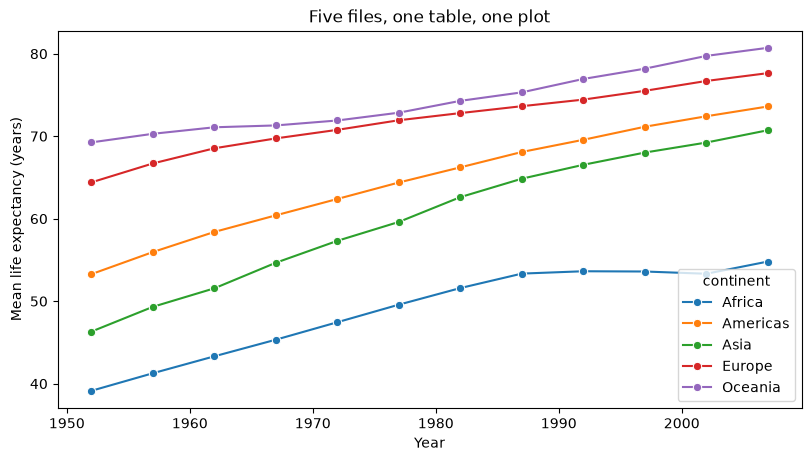

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
sns.lineplot(data=gapminder, x="year", y="lifeExp", hue="continent",
             errorbar=None, marker="o", ax=ax)
ax.set(xlabel="Year", ylabel="Mean life expectancy (years)",
       title="Five files, one table, one plot")
plt.show()

`lineplot` averages the countries of each continent in each year, as `groupby()` did in
Data Grouping and Aggregation; `errorbar=None` leaves out the confidence bands. Without the
`continent` column added during the loop, this plot would be impossible.

## Match rows on a key: `merge()`

Stacking needs tables with the same columns. Matching needs something different: a
**key**, a column whose values identify the same thing in both tables. Two small tables
about members of the Fellowship from *The Lord of the Rings* show how it works. One lists
skills, the other ages, and both identify members by `FellowshipID`:

In [5]:
skills = pd.DataFrame({
    "FellowshipID": [1001, 1002, 1003, 1004],
    "FirstName": ["Frodo", "Samwise", "Gandalf", "Pippin"],
    "Skills": ["Hiding", "Gardening", "Spells", "Fireworks"],
})
ages = pd.DataFrame({
    "FellowshipID": [1001, 1002, 1006, 1007, 1008],
    "FirstName": ["Frodo", "Samwise", "Legolas", "Elrond", "Boromir"],
    "Age": [50, 39, 2931, 6520, 51],
})
print(skills, "\n")
print(ages)

   FellowshipID FirstName     Skills
0          1001     Frodo     Hiding
1          1002   Samwise  Gardening
2          1003   Gandalf     Spells
3          1004    Pippin  Fireworks 

   FellowshipID FirstName   Age
0          1001     Frodo    50
1          1002   Samwise    39
2          1006   Legolas  2931
3          1007    Elrond  6520
4          1008   Boromir    51


Frodo and Samwise appear in both tables; Gandalf and Pippin only in `skills`; Legolas,
Elrond, and Boromir only in `ages`. `merge()` pairs rows whose key values are equal:

In [6]:
skills.merge(ages, on="FellowshipID")

,FellowshipID,FirstName_x,Skills,FirstName_y,Age
0,1001,Frodo,Hiding,Frodo,50
1,1002,Samwise,Gardening,Samwise,39


Two rows: by default `merge()` keeps only keys found in **both** tables. Notice
`FirstName_x` and `FirstName_y`. Both tables have a `FirstName` column that is not part
of the key, so pandas keeps both and adds suffixes: `_x` from the left table, `_y` from
the right. Here the two columns agree, because a name belongs to its ID.

### Several key columns

When two tables share more than one identifying column, list them all in `on=`. Rows
then pair only when every key matches, and the shared columns appear once:

In [7]:
skills.merge(ages, on=["FellowshipID", "FirstName"])

,FellowshipID,FirstName,Skills,Age
0,1001,Frodo,Hiding,50
1,1002,Samwise,Gardening,39


Several key columns are common: a sale is identified by store **and** date, a grade by
student **and** course, a Gapminder row by country **and** year.

### Keys with different names

Two sources rarely name their key the same way: `FellowshipID` in one file, `ID` in
another. `left_on=` and `right_on=` name the key in each table:

In [8]:
ages_renamed = ages.rename(columns={"FellowshipID": "ID"})
skills.merge(ages_renamed, left_on="FellowshipID", right_on="ID")

,FellowshipID,FirstName_x,Skills,ID,FirstName_y,Age
0,1001,Frodo,Hiding,1001,Frodo,50
1,1002,Samwise,Gardening,1002,Samwise,39


Both key columns survive, holding identical values; drop one afterwards with
`.drop(columns="ID")`.

### Which rows survive: `how=`

The rows that find no partner are where most mistakes happen. `how=` decides what
happens to them:

![The four join types on the fellowship tables. Purple rows have a key in both tables, blue rows only in the left table, gold rows only in the right; NaN marks values with no partner.](https://lizhen0909.github.io/stat303-1-sec20-coursebook/images/join-types.png){width=900}

| `how=` | Keeps | `NaN` appears in | Rows here |
|---|---|---|---|
| `"inner"` (default) | Keys in both tables | Nowhere | 2 |
| `"left"` | Every left key | Right-hand columns of unmatched rows | 4 |
| `"right"` | Every right key | Left-hand columns of unmatched rows | 5 |
| `"outer"` | Every key in either table | Both sides | 7 |

The counts are worth confirming in code, and `indicator=True` adds a `_merge` column that
says where each row came from:

In [9]:
fellowship = skills.merge(ages, on=["FellowshipID", "FirstName"], how="outer", indicator=True)
fellowship

,FellowshipID,FirstName,Skills,Age,_merge
0,1001,Frodo,Hiding,50.0,both
1,1002,Samwise,Gardening,39.0,both
2,1003,Gandalf,Spells,NaN,left_only
3,1004,Pippin,Fireworks,NaN,left_only
4,1006,Legolas,NaN,2931.0,right_only
5,1007,Elrond,NaN,6520.0,right_only
6,1008,Boromir,NaN,51.0,right_only


In [10]:
fellowship["_merge"].value_counts()

_merge
right_only    3
left_only     2
both          2
Name: count, dtype: int64

`both`, `left_only`, and `right_only` are the three colours of the diagram. Counting the
`_merge` column is the quickest way to see how well two tables matched: a merge you
expected to pair almost everything, but that shows many `left_only` rows, is usually a
sign that the keys are written differently in the two tables.

**Which `how=` to use.**

| `how=` | Use when | Examples |
|---|---|---|
| `"inner"` | The analysis needs both pieces of information for every row | Relating vaccination rates to infection rates: only countries with both can contribute. An A/B test: only users with both a group assignment and an outcome count. |
| `"left"` | The left table is your primary data and every row must stay | All customers with their purchases: a customer with no purchases spent $0. All employees with their reviews: an employee not yet reviewed is "pending", not missing. |
| `"outer"` | Nothing may be lost from either table | Mid- and end-of-semester surveys: keep every student who answered either one. Auditing expected against actual records: find what is missing on each side. |
| `"right"` | The right table is primary | The same as a left join with the tables swapped; writing it as a left join, primary table first, usually reads more clearly. |

## Check a merge

A merge can return a table of the right shape that is quietly wrong. Three checks catch
most problems: the row count, the uniqueness of the keys, and the missing values that
unmatched keys leave behind.

### The row count, and keys that repeat

Suppose life expectancy and GDP arrived in two separate tables, both keyed by country and
year:

In [11]:
life = gapminder[["country", "year", "lifeExp"]]
money = gapminder[["country", "year", "gdpPercap"]]

both_keys = life.merge(money, on=["country", "year"])
print(life.shape, money.shape, "->", both_keys.shape)

(1704, 3) (1704, 3) -> (1704, 4)


1,704 rows in, 1,704 rows out: every country-year found exactly one partner. Now the
same merge with an incomplete key, `country` alone:

In [12]:
country_only = life.merge(money, on="country")
print(country_only.shape)
country_only.head(3)

(20448, 5)


,country,year_x,lifeExp,year_y,gdpPercap
0,Algeria,1952,43.077,1952,2449.008185
1,Algeria,1952,43.077,1957,3013.976023
2,Algeria,1952,43.077,1962,2550.816880


20,448 rows: twelve times too many, and no error. Each country has 12 rows in each
table, so every row in `life` pairs with all 12 rows of the same country in `money`, and
12 × 12 = 144 rows per country × 142 countries = 20,448. The `year_x` and `year_y`
columns are the giveaway: a 1952 life expectancy sits beside a 2007 GDP. A **key** must
identify one row; `country` alone does not.

`validate=` tells `merge()` what you expect and raises an error when the keys disagree.
`"one_to_one"` means each key appears at most once in each table; `"many_to_one"` means
the right table's keys are unique, as for a lookup table. A `try`/`except` block shows the
error and lets the notebook keep running:

In [13]:
try:
    life.merge(money, on="country", validate="one_to_one")
except pd.errors.MergeError as error:
    print("MergeError:", str(error).splitlines()[0])

MergeError: Merge keys are not unique in either left or right dataset; not a one-to-one merge.


The same check passes for the correct key, `on=["country", "year"]`. Add `validate=`
whenever you know how the tables should relate; it turns a silent row explosion into an
error you cannot miss. Before merging, `df.duplicated(subset=key).sum()`, from
[Data Cleaning](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data_cleaning.html), counts repeated keys in each table.

### Many rows to one: a lookup table

The most common merge in practice attaches a small **lookup table** to many rows: a
region for each state, a price for each product code, a group summary for each member.
Each row of the large table matches exactly one row of the lookup table, while each
lookup row matches many — the `"many_to_one"` relationship.

A summary from [Data Grouping and Aggregation](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data%20aggregation.html) makes a lookup
table: mean life expectancy for each continent and year, 60 rows. `rename()` gives its
value column a distinct name before the merge:

In [14]:
continent_mean = (gapminder.groupby(["continent", "year"])["lifeExp"].mean()
                  .reset_index()
                  .rename(columns={"lifeExp": "continent_lifeExp"}))

with_mean = gapminder.merge(continent_mean, on=["continent", "year"],
                            how="left", validate="many_to_one")
print(continent_mean.shape, "->", with_mean.shape)

(60, 3) -> (1704, 7)


`validate="many_to_one"` passes because each continent-year appears once in the lookup
table, and the row count is still 1,704: every country row gained one value and none was
duplicated. That is the check for any lookup merge — the row count must not change.

Each country can now be compared with its continent in the same year:

In [15]:
with_mean["gap"] = with_mean["lifeExp"] - with_mean["continent_lifeExp"]
(with_mean.sort_values("gap")
    [["country", "continent", "year", "lifeExp", "continent_lifeExp", "gap"]]
    .head(3).round(1))

,country,continent,year,lifeExp,continent_lifeExp,gap
464,Rwanda,Africa,1992,23.6,53.6,-30.0
965,Cambodia,Asia,1977,31.2,59.6,-28.4
934,Afghanistan,Asia,2002,42.1,69.2,-27.1


The largest gaps below a continent's mean are Rwanda in 1992, 30 years below Africa's
mean in the years of its civil war and genocide; Cambodia in 1977, under the Khmer Rouge;
and Afghanistan in 2002. The `continent_lifeExp` column is exactly what
`groupby(["continent", "year"])["lifeExp"].transform("mean")` gave in Data Grouping and
Aggregation. `transform()` is the shortcut when the summary comes from the same table;
merging a summary back is the general pattern, and it works when the lookup table comes
from somewhere else.

### Missing values from unmatched keys

A left or outer merge fills the columns of unmatched rows with `NaN`. Unlike the gaps in
Data Cleaning, these mean something specific: *this key was not found in the other
table*. The right handling depends on what absence means.

In [16]:
left_join = skills.merge(ages, on=["FellowshipID", "FirstName"], how="left")
left_join

,FellowshipID,FirstName,Skills,Age
0,1001,Frodo,Hiding,50.0
1,1002,Samwise,Gardening,39.0
2,1003,Gandalf,Spells,NaN
3,1004,Pippin,Fireworks,NaN


Gandalf's and Pippin's ages are `NaN` because the `ages` table has no row for them, not
because their age is zero. Three choices, from Data Cleaning:

- **Keep** the `NaN` when absence is informative and should be reported, as here: the
  ages table is incomplete.
- **Fill** when absence has a known meaning: a customer with no purchase rows spent $0, so
  `fillna(0)` is correct for spend, though it would be wrong for age.
- **Drop** with `dropna(subset=[...])` when an analysis needs both values — which is the
  same as having used an inner join.

Whichever you choose, count how many rows were unmatched before deciding.

::: {.callout-note}
## `join()` and `concat(axis=1)`

You will also meet `df.join(other)`, which matches rows on the **index** rather than on a
column, and `pd.concat([a, b], axis=1)`, which places tables side by side by index. Both
do work `merge()` can do once the key is an ordinary column, which is how this book
writes it: `merge()` names the key, so the match is visible in the code.
:::

## Summary Cheat Sheet {#summary-cheat-sheet}

**Stacking.**

| Goal | Code |
|---|---|
| Stack tables with the same columns | `pd.concat([a, b, c], ignore_index=True)` |
| Record each piece's source | `piece["source"] = name` before stacking |
| Check the result | rows equal the sum of the pieces; inspect `columns` |

**Matching.**

| Goal | Code |
|---|---|
| Match on one key | `left.merge(right, on="key")` |
| Match on several keys | `left.merge(right, on=["k1", "k2"])` |
| Keys with different names | `left.merge(right, left_on="id", right_on="ID")` |
| Keep unmatched rows | `how="left"`, `"right"`, or `"outer"` (default `"inner"`) |
| See where each row came from | `indicator=True`, then `df["_merge"].value_counts()` |
| Enforce how keys relate | `validate="one_to_one"` or `"many_to_one"` |
| Count repeated keys first | `df.duplicated(subset=["key"]).sum()` |
| Attach a lookup table | `big.merge(lookup, on="key", how="left", validate="many_to_one")`; rows unchanged |

The rule to remember: **after every merge, compare the row count with what you expected
and count where the rows came from.**

## Practice Activity: Stack, Match, and Check {#practice-activity-stack-match-and-check}

**Goal:** Combine real files by stacking and by matching, and use the checks to find what did not combine cleanly.

**File:** `activity14.ipynb` from the [practice kit](https://lizhen0909.github.io/stat303-1-sec20-coursebook/downloads/combining-datasets-practice.zip).

**Submit:** `activity14.html` through the final upload question in the Combining Datasets Canvas quiz.

**This section contains the complete activity instructions.** The starter loads the data and supplies spaces to record your work. Open `activity14.ipynb` from the folder prepared in [Set Up Your Chapter Files](#set-up-your-chapter-files), using the same project environment. The worked examples above are preparation, not additional submission requirements.

The starter reads the five continent files into a dictionary, `pieces`, keyed by continent name, and loads `capitals`, a table of countries with their capital cities.

### A. Stack Five Files {.unnumbered}

- Replace `Your Name` in the opening Raw cell's `author` field. Run the setup cell; it must report five continent tables and `capitals` with shape `(234, 6)`.
- Add a `continent` column to each piece and stack them with `pd.concat(..., ignore_index=True)` into one table, `gapminder`.
- Show that the stacked row count equals the sum of the pieces, and that `gapminder` has no missing values.

### B. Match Countries to Capitals {.unnumbered}

- Make `gapminder_2007`, the rows for 2007, and merge it with `capitals` using `how="left"`, `left_on="country"`, `right_on="Country"`, and `indicator=True`.
- Report how many countries matched and how many did not, and list the unmatched countries.
- Choose two unmatched countries, find how each is written in `capitals`, and explain why the merge missed them.

### C. Inner Against Outer {.unnumbered}

- Repeat the merge with `how="inner"` and with `how="outer"`, and report the row count of each.
- Explain each count in terms of the rows in `gapminder_2007`, the rows in `capitals`, and the number that matched.

### D. Check the Keys {.unnumbered}

- Count the repeated values in `capitals["Country"]` with `duplicated()`, and show the repeated rows.
- Show that the Part B merge raises a `MergeError` with `validate="many_to_one"` (catch it with `try`/`except`), then remove the repeat with `drop_duplicates(subset="Country")` and show that the validated merge succeeds.

### Render and Submit {.unnumbered}

Restart the kernel, run all cells in order, resolve unexpected errors, and save. Include your outputs and explanations for A–D, and a short Markdown completion note. From `stat303-combining-datasets` in the terminal, run:

```text
quarto render activity14.ipynb --to html
```

Follow the [Quarto refresher](https://lizhen0909.github.io/stat303-1-sec20-coursebook/vscode_setup.html#render-and-submit-with-quarto): inspect the HTML and a copy opened outside the project folder, and confirm that every output appears and your name is on the report. Upload only `activity14.html` to the Combining Datasets Canvas quiz; keep your notebook locally.

**HTML grading (16 points):** the stacked table with its row and missing-value checks (4); the left merge, the matched and unmatched counts, and the two explained mismatches (4); inner and outer row counts with their explanation (4); the repeated key, the validated merge failing and then succeeding (3); name, readable report, and completion note (1).

## Extended Practice {#extended-practice}

These longer exercises are additional practice, not requirements for the Canvas quiz.
Work in a separate notebook beside your activity and load the data the way the chapter
does. Include your code, outputs, and explanations.

### Repair the Names

Build a small table that maps each unmatched Gapminder name to its spelling in
`capitals` (for example, `"United States"` to `"United States of America"`), use it to
add a corrected key column to `gapminder_2007`, and repeat the left merge. How many
countries still fail to match, and why?

### Capitals and Life Expectancy

After the repaired merge, plot life expectancy in 2007 against the latitude of each
country's capital, coloured by continent. Is there a pattern? What would you check before
claiming one?

### Stack, Then Summarize

Stack the five continent files without adding a `continent` column, then try to compute
mean life expectancy by continent. What information was lost, and how else could you
recover it from the files?

### Merge Two Summaries

Compute mean life expectancy by continent and year in one table and total population by
continent and year in another, using `groupby()`. Merge them on both keys with
`validate="one_to_one"`, and plot one against the other.

## Before You Move On {#before-you-move-on}

The habit to carry forward is checking every combination. A stack should have exactly
the rows of its pieces. A merge should have the rows you predicted from its keys and its
`how=`, and `indicator=True` and `validate=` turn the ways it can go wrong — unmatched
keys, keys that repeat — into numbers and errors you can see. None of these mistakes
raises an error on its own; a merged table looks complete whether or not it is right.

The other habit is asking what an absence means. A `NaN` from an unmatched key says the
other table had no row, which is different from a value of zero and different from a
measurement that was never taken.

For any combination you make, you should be able to answer five questions:

1. Are you stacking tables with the same columns, or matching tables on a key?
2. What is the key, and does it identify exactly one row in each table?
3. Which `how=` did you choose, and how many rows did you expect?
4. How many rows matched, and why did the others not?
5. What do the missing values from unmatched keys mean, and what did you do with them?

This chapter completes the path the book has followed: reading data, cleaning it,
preparing it, summarizing it by group, reshaping it, and now combining it. The
assignments in the appendices bring these steps together on larger datasets.

References: [pandas: merge, join, concatenate and compare](https://pandas.pydata.org/docs/user_guide/merging.html),
[`pd.concat`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html),
[`DataFrame.merge`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html),
[`DataFrame.join`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.join.html),
and [`pandas.errors.MergeError`](https://pandas.pydata.org/docs/reference/api/pandas.errors.MergeError.html).